# G25AIT2042 flowers — Tokenization & Vectorization

This notebook is the original *flowers* neural network, rebuilt so that:

1. **Tokenization** — each flower is stored as a text record (e.g. `"length: 3 width: 1.5 type: red"`) and split into tokens.
2. **Vocabulary & encoding** — tokens are mapped to integer IDs, and labels (`red`/`blue`) are encoded as 1/0.
3. **Vectorization** — the tokens become a NumPy feature matrix `X` and label vector `y`, and every loop in the original code (cost, training, decision-boundary grid) is replaced with vectorized NumPy matrix operations.

In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np
import re
from collections import Counter

## 1. Raw data as text
Each point is length, width, type. Type `red` = 1, `blue` = 0 (same data as the original notebook).

In [2]:
raw_data = [
    "length: 3   width: 1.5 type: red",
    "length: 2   width: 1   type: blue",
    "length: 4   width: 1.5 type: red",
    "length: 3   width: 1   type: blue",
    "length: 3.5 width: .5  type: red",
    "length: 2   width: .5  type: blue",
    "length: 5.5 width: 1   type: red",
    "length: 1   width: 1   type: blue",
]

mystery_flower_text = "length: 4.5 width: 1"
raw_data

['length: 3   width: 1.5 type: red',
 'length: 2   width: 1   type: blue',
 'length: 4   width: 1.5 type: red',
 'length: 3   width: 1   type: blue',
 'length: 3.5 width: .5  type: red',
 'length: 2   width: .5  type: blue',
 'length: 5.5 width: 1   type: red',
 'length: 1   width: 1   type: blue']

## 2. Tokenization
A simple regex tokenizer: lower-cases the text and splits it into word tokens and number tokens (handles values like `.5`), dropping punctuation such as `:`.

In [3]:
TOKEN_PATTERN = re.compile(r"[a-z]+|\d*\.\d+|\d+")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())

tokenized = [tokenize(t) for t in raw_data]
mystery_tokens = tokenize(mystery_flower_text)

for text, toks in zip(raw_data, tokenized):
    print(f"{text!r:40} -> {toks}")
print()
print("mystery:", mystery_tokens)

'length: 3   width: 1.5 type: red'       -> ['length', '3', 'width', '1.5', 'type', 'red']
'length: 2   width: 1   type: blue'      -> ['length', '2', 'width', '1', 'type', 'blue']
'length: 4   width: 1.5 type: red'       -> ['length', '4', 'width', '1.5', 'type', 'red']
'length: 3   width: 1   type: blue'      -> ['length', '3', 'width', '1', 'type', 'blue']
'length: 3.5 width: .5  type: red'       -> ['length', '3.5', 'width', '.5', 'type', 'red']
'length: 2   width: .5  type: blue'      -> ['length', '2', 'width', '.5', 'type', 'blue']
'length: 5.5 width: 1   type: red'       -> ['length', '5.5', 'width', '1', 'type', 'red']
'length: 1   width: 1   type: blue'      -> ['length', '1', 'width', '1', 'type', 'blue']

mystery: ['length', '4.5', 'width', '1']


## 3. Vocabulary & token IDs
Build a vocabulary of every unique token and map each token to an integer ID (the standard first step before vectorizing text).

In [4]:
counts = Counter(tok for toks in tokenized for tok in toks)
vocab = {tok: i for i, tok in enumerate(sorted(counts))}
id_to_token = {i: tok for tok, i in vocab.items()}

print("vocab size:", len(vocab))
print(vocab)
print()
token_ids = [[vocab[t] for t in toks] for toks in tokenized]
for toks, ids in zip(tokenized, token_ids):
    print(toks, "->", ids)

vocab size: 13
{'.5': 0, '1': 1, '1.5': 2, '2': 3, '3': 4, '3.5': 5, '4': 6, '5.5': 7, 'blue': 8, 'length': 9, 'red': 10, 'type': 11, 'width': 12}

['length', '3', 'width', '1.5', 'type', 'red'] -> [9, 4, 12, 2, 11, 10]
['length', '2', 'width', '1', 'type', 'blue'] -> [9, 3, 12, 1, 11, 8]
['length', '4', 'width', '1.5', 'type', 'red'] -> [9, 6, 12, 2, 11, 10]
['length', '3', 'width', '1', 'type', 'blue'] -> [9, 4, 12, 1, 11, 8]
['length', '3.5', 'width', '.5', 'type', 'red'] -> [9, 5, 12, 0, 11, 10]
['length', '2', 'width', '.5', 'type', 'blue'] -> [9, 3, 12, 0, 11, 8]
['length', '5.5', 'width', '1', 'type', 'red'] -> [9, 7, 12, 1, 11, 10]
['length', '1', 'width', '1', 'type', 'blue'] -> [9, 1, 12, 1, 11, 8]


### Bag-of-words vectors
For reference, each record as a count vector over the vocabulary (one column per token).

In [5]:
def bag_of_words(tokens, vocab):
    v = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            v[vocab[t]] += 1
    return v

bow = np.array([bag_of_words(t, vocab) for t in tokenized])
print("columns:", [id_to_token[i] for i in range(len(vocab))])
print(bow)

columns: ['.5', '1', '1.5', '2', '3', '3.5', '4', '5.5', 'blue', 'length', 'red', 'type', 'width']
[[0 0 1 0 1 0 0 0 0 1 1 1 1]
 [0 1 0 1 0 0 0 0 1 1 0 1 1]
 [0 0 1 0 0 0 1 0 0 1 1 1 1]
 [0 1 0 0 1 0 0 0 1 1 0 1 1]
 [1 0 0 0 0 1 0 0 0 1 1 1 1]
 [1 0 0 1 0 0 0 0 1 1 0 1 1]
 [0 1 0 0 0 0 0 1 0 1 1 1 1]
 [0 2 0 0 0 0 0 0 1 1 0 1 1]]


## 4. Vectorization → feature matrix `X` and labels `y`
The network needs numeric inputs, so we read each `key: value` token pair into a field, then stack all flowers into a NumPy matrix.

In [6]:
LABELS = {"blue": 0, "red": 1}
FEATURES = ["length", "width"]

def tokens_to_fields(tokens):
    # pair each key token with the value token that follows it
    return {tokens[i]: tokens[i + 1] for i in range(0, len(tokens) - 1, 2)}

def vectorize(tokens):
    fields = tokens_to_fields(tokens)
    x = np.array([float(fields[f]) for f in FEATURES])
    y = LABELS[fields["type"]] if "type" in fields else None
    return x, y

pairs = [vectorize(t) for t in tokenized]
X = np.vstack([p[0] for p in pairs])          # shape (8, 2)
y = np.array([p[1] for p in pairs], float)    # shape (8,)
mystery_flower, _ = vectorize(mystery_tokens)  # shape (2,)

# keep the original-style data list too: [length, width, type]
data = np.column_stack([X, y])

print("X =\n", X)
print("y =", y)
print("mystery_flower =", mystery_flower)

X =
 [[3.  1.5]
 [2.  1. ]
 [4.  1.5]
 [3.  1. ]
 [3.5 0.5]
 [2.  0.5]
 [5.5 1. ]
 [1.  1. ]]
y = [1. 0. 1. 0. 1. 0. 1. 0.]
mystery_flower = [4.5 1. ]


## 5. Scatter plot (vectorized)
Instead of plotting one point at a time, colors are chosen for the whole array at once.

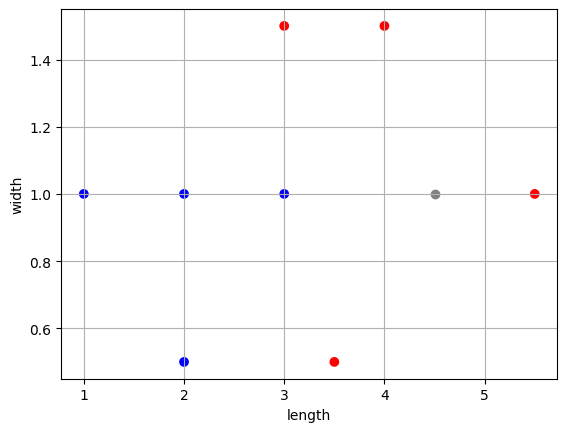

In [7]:
def vis_data():
    plt.grid()
    colors = np.where(y == 1, 'r', 'b')
    plt.scatter(X[:, 0], X[:, 1], c=colors)
    plt.scatter(mystery_flower[0], mystery_flower[1], c='gray')
    plt.xlabel("length"); plt.ylabel("width")
    plt.show()

vis_data()

In [8]:
# network

#       o  flower type
#      / \  w (w1, w2), b
#     o   o  length, width

## 6. Activation function
`np.exp` works element-wise, so these already accept whole vectors.

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1 - sigmoid(x))

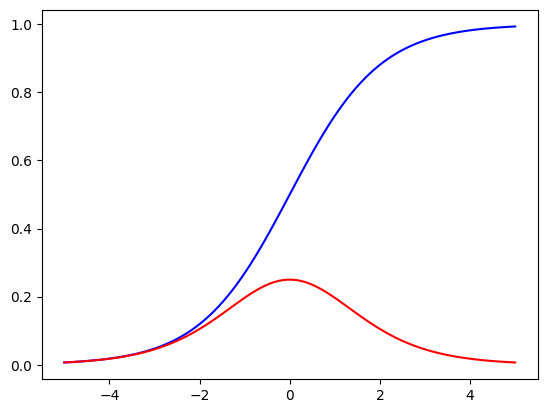

In [10]:
Z = np.linspace(-5, 5, 100)
plt.figure()
plt.plot(Z, sigmoid(Z), c="b")    # sigmoid in blue
plt.plot(Z, sigmoid_p(Z), c="r")  # sigmoid_p in red
plt.show()

## 7. Vectorized training
The weights are now one vector `w = [w1, w2]`, and the prediction is a dot product `z = X @ w + b`.

* The cost over all points is one line: `np.sum((sigmoid(X @ w + b) - y) ** 2)` — no inner loop.
* Gradients are computed with vector math instead of separate `dcost_dw1`, `dcost_dw2` variables.
* Same settings as the original: 10,000 iterations of stochastic gradient descent, learning rate 0.1, cost recorded every 100 steps.

w1 = 2.6087, w2 = 0.7979, b = -8.2712
final cost: 0.5110614582429344


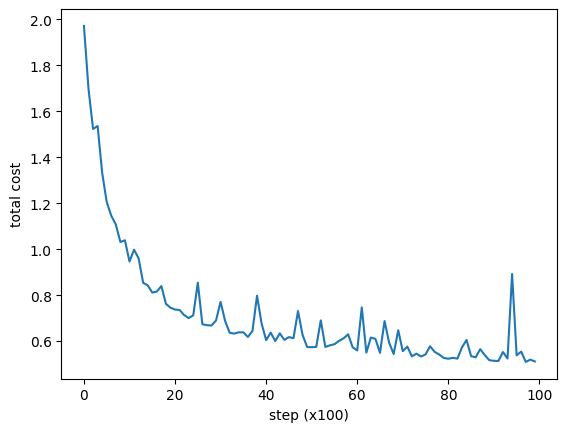

In [11]:
def total_cost(w, b):
    preds = sigmoid(X @ w + b)
    return np.sum(np.square(preds - y))

def train(iterations=10000, learning_rate=0.1, seed=None):
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(X.shape[1])  # [w1, w2]
    b = rng.standard_normal()
    costs = []

    for i in range(iterations):
        ri = rng.integers(len(X))      # random point
        x_i, target = X[ri], y[ri]

        z = x_i @ w + b
        pred = sigmoid(z)

        if i % 100 == 0:
            costs.append(total_cost(w, b))

        dcost_dz = 2 * (pred - target) * sigmoid_p(z)
        w -= learning_rate * dcost_dz * x_i   # vector gradient for w1, w2
        b -= learning_rate * dcost_dz

    return costs, w, b

costs, w, b = train(seed=42)
w1, w2 = w
print(f"w1 = {w1:.4f}, w2 = {w2:.4f}, b = {b:.4f}")
print("final cost:", total_cost(w, b))

plt.plot(costs)
plt.xlabel("step (x100)"); plt.ylabel("total cost")
plt.show()

## 8. Predict the mystery flower

In [12]:
pred = sigmoid(mystery_flower @ w + b)

print(pred)
print("close to 0 -> blue, close to 1 -> red")
print("prediction:", "red" if pred > .5 else "blue")

0.9861550181037693
close to 0 -> blue, close to 1 -> red
prediction: red


### Accuracy on all training points (one vectorized call)

In [13]:
train_preds = sigmoid(X @ w + b)
print("predictions:", np.round(train_preds, 3))
print("accuracy:", np.mean((train_preds > .5) == y))

predictions: [0.68  0.095 0.966 0.587 0.779 0.066 0.999 0.008]
accuracy: 0.875


## 9. Decision boundary (vectorized grid)
The original used a 20×20 double loop with 400 `scatter` calls; here the whole grid is predicted in a single matrix product.

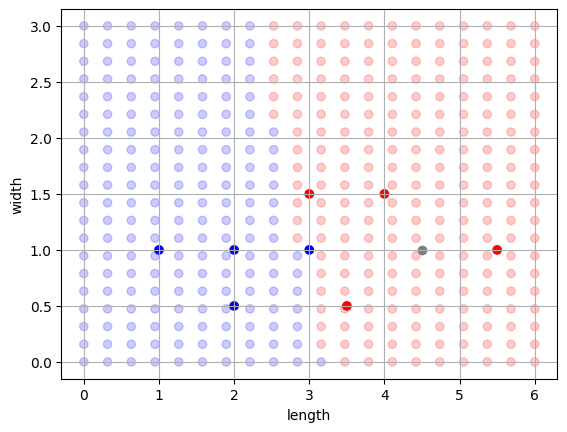

In [14]:
gx, gy = np.meshgrid(np.linspace(0, 6, 20), np.linspace(0, 3, 20))
grid = np.column_stack([gx.ravel(), gy.ravel()])   # shape (400, 2)
grid_preds = sigmoid(grid @ w + b)

plt.scatter(grid[:, 0], grid[:, 1], c=np.where(grid_preds > .5, 'r', 'b'), alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

## 10. Classify new flowers straight from text
The full pipeline: text → tokens → vector → prediction.

In [15]:
def classify(text):
    x, _ = vectorize(tokenize(text))
    p = sigmoid(x @ w + b)
    return p, ("red" if p > .5 else "blue")

for t in ["length: 4.5 width: 1", "length: 1.5 width: .8", "length: 6 width: 2"]:
    p, label = classify(t)
    print(f"{t:25} -> {p:.4f} ({label})")

length: 4.5 width: 1      -> 0.9862 (red)
length: 1.5 width: .8     -> 0.0237 (blue)
length: 6 width: 2        -> 0.9999 (red)
